In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import tol_colors as tc
from paper import fit_height, mark_value, smooth, darken  # importing paper registers the bundled Inter font

plt.style.use("paper.mplstyle")
cset = tc.colorsets["bright"]

## pass-at-k

**Figure 2: Pass@k of base models and their RLVR-trained counterparts (SimpleRL-Zoo, GRPO) on four math benchmarks.** The x-axis is log-scaled. When k is small, RL-trained models lead, but as k grows to the tens or hundreds the base models catch up and surpass them (Qwen2.5-32B on Minerva: 0.677 vs. 0.585 at k = 128).

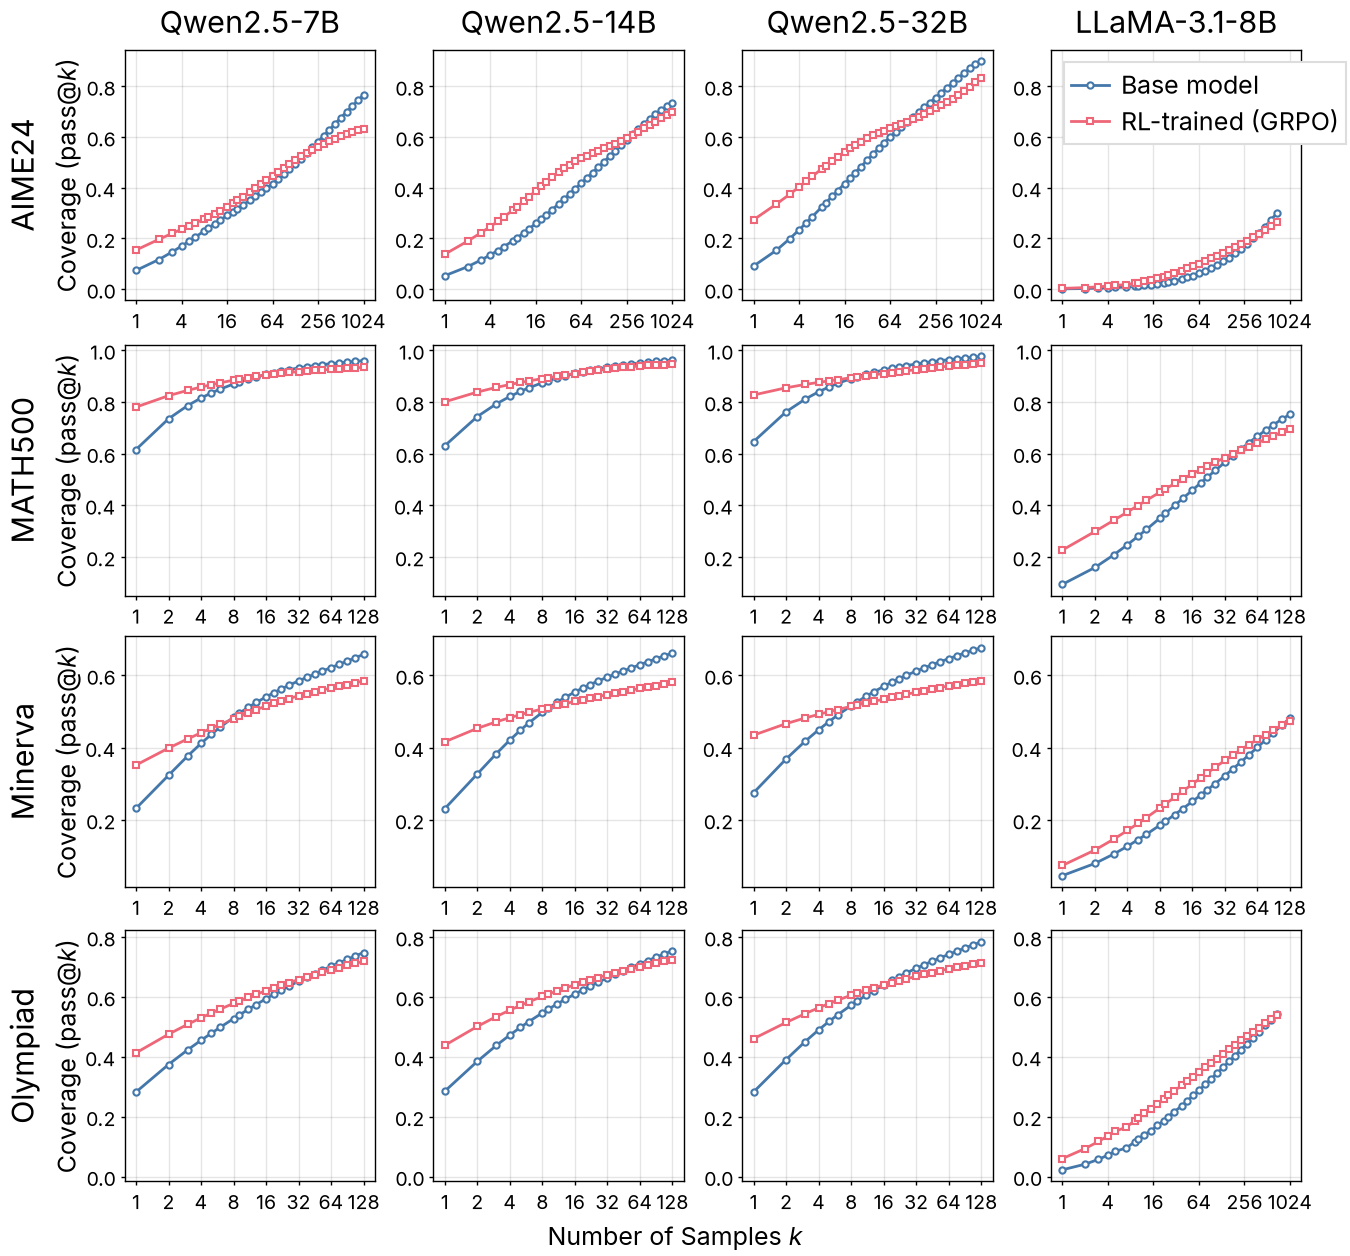

In [2]:
import math

with open("../rlvr.json") as f:
    data = json.load(f)

benchmarks = ["AIME24", "MATH500", "Minerva", "Olympiad"]
models = ["Qwen2.5-7B", "Qwen2.5-14B", "Qwen2.5-32B", "LLaMA-3.1-8B"]
series = [("Base", "Base model", cset.blue, "o"), ("RL", "RL-trained (GRPO)", cset.red, "s")]

fig, axes = plt.subplots(4, 4, figsize=(6.75, 6), sharey="row")
for row, benchmark in enumerate(benchmarks):
    for col, model in enumerate(models):
        ax = axes[row, col]
        for key, label, color, marker in series:
            curve = data[benchmark][model][key]
            ax.plot(curve["k"], curve["pass"], color=color, marker=marker, label=label if row == col == 0 else None)
        # Every power of 2 up to 128 fits a panel this narrow; past 128 the labels overlap, so step by 4
        base = 4 if curve["k"][-1] > 128 else 2
        top = next(base**n for n in range(11) if base**n >= curve["k"][-1])
        ks = [base**n for n in range(11) if base**n <= top]
        ax.set_xscale("log", base=2)
        # The axis ends at the first power at or above the largest k, keeping the 5% margin
        margin = 2 ** (0.05 * math.log2(top))
        ax.set_xlim(1 / margin, top * margin)
        ax.set_xticks(ks, labels=[str(k) for k in ks])
        ax.set_xticks([], minor=True)
        ax.tick_params(labelleft=True)
    axes[row, 0].set_ylabel("Coverage (pass@$k$)")
    axes[row, 0].annotate(benchmark, xy=(0, 0.5), xycoords=axes[row, 0].yaxis.label, xytext=(-4, 0),
                          textcoords="offset points", ha="right", va="center", rotation=90, fontsize=11)
for ax, model in zip(axes[0], models):
    ax.set_title(model)
fig.supxlabel("Number of Samples $k$")

# the first panel with a free corner: AIME24 curves of LLaMA stay near 0
axes[0, 3].legend(*axes[0, 0].get_legend_handles_labels(), loc="upper left")
fit_height(fig, axes, aspect=1.0)
fig.savefig("pass-at-k.pdf")
fig.savefig("pass-at-k.png")
plt.show()

## fig5

**Figure 5: Per-problem accuracy histogram of Qwen2.5-7B on Minerva (272 problems), base model versus its RLVR-trained version (SimpleRL-Zoo).** RLVR moves problems toward the extremes: it raises the count at accuracy 1.0 from 3 to 47 and lowers the count in (0.0, 0.1] from 52 to 33, but also raises the number of unsolved problems (accuracy 0) from 93 to 113.

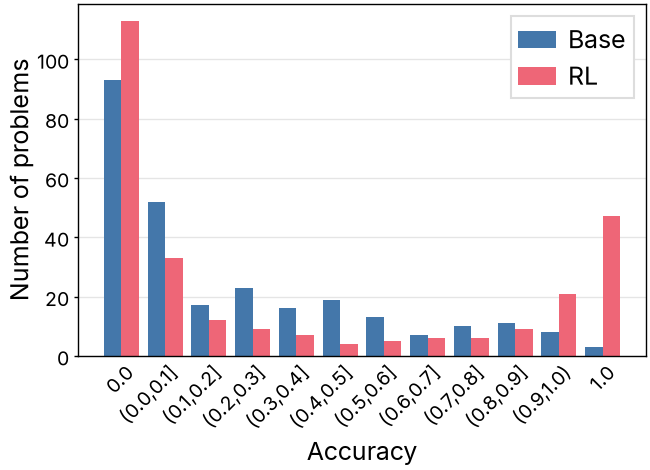

In [3]:
with open("../rlvr-fig5.json") as f:
    data = json.load(f)

x = np.arange(len(data["bins"]))
width = 0.4

fig, ax = plt.subplots(figsize=(3.25, 2))
for i, (name, color) in enumerate([("Base", cset.blue), ("RL", cset.red)]):
    ax.bar(x - width / 2 + i * width, data[name], width, color=color, linewidth=0, label=name)
ax.set_xticks(x, labels=data["bins"], rotation=45, ha="right", rotation_mode="anchor")
ax.tick_params(axis="x", length=0)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Accuracy")
ax.set_ylabel("Number of problems")
ax.legend(loc="upper right")

fit_height(fig, ax, aspect=0.618)
fig.savefig("fig5.pdf")
fig.savefig("fig5.png")
plt.show()

## fig6

**Figure 6: Perplexity of individual responses for two AIME24 problems, scored by Qwen2.5-7B-Base and its RLVR-trained version.** PPL_M(Y_S) is model M's perplexity on responses sampled from S (16 per model; 8 from OpenAI-o1 as ground truth, 7 recoverable for Problem 1); boxes show the quartiles, whiskers extend to 1.5× the interquartile range, and dots are individual responses. The base model's perplexity on RL responses sits in the lower part of its perplexity on its own responses (median 1.06 vs. 1.08 in (a), 1.25 vs. 1.29 in (b)), so the RL model generates responses the base model already tends to produce.

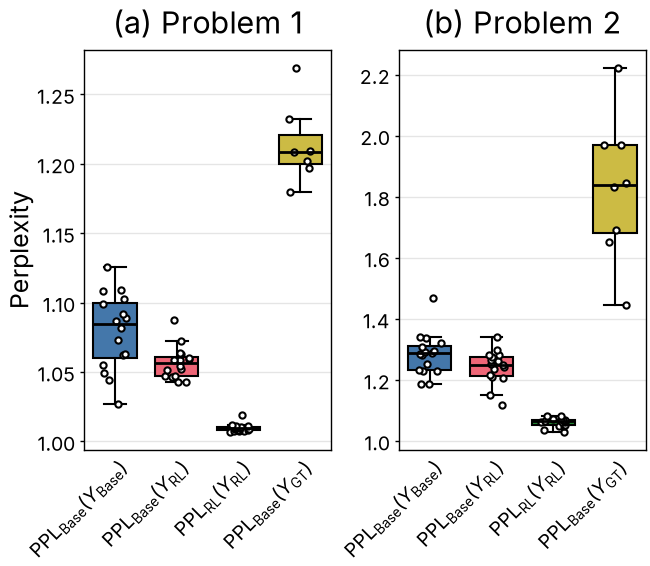

In [4]:
with open("../rlvr-fig6.json") as f:
    data = json.load(f)

groups = [
    ("PPL_Base(Y_Base)", r"$\mathrm{PPL_{Base}}(Y_\mathrm{Base})$", cset.blue),
    ("PPL_Base(Y_RL)", r"$\mathrm{PPL_{Base}}(Y_\mathrm{RL})$", cset.red),
    ("PPL_RL(Y_RL)", r"$\mathrm{PPL_{RL}}(Y_\mathrm{RL})$", cset.green),
    ("PPL_Base(Y_GT)", r"$\mathrm{PPL_{Base}}(Y_\mathrm{GT})$", cset.yellow),
]
rng = np.random.default_rng(0)

fig, axes = plt.subplots(1, 2, figsize=(3.25, 3))
for ax, (letter, problem) in zip(axes, [("a", "Problem 1"), ("b", "Problem 2")]):
    for x, (key, label, color) in enumerate(groups):
        values = data[problem][key]
        box = ax.boxplot(values, positions=[x], widths=0.7, showfliers=False)
        box["boxes"][0].set_facecolor(color)
        ax.plot(x + rng.uniform(-0.2, 0.2, len(values)), values, "o", color="black", markerfacecolor="white", linestyle="none")
    ax.set_xticks(range(len(groups)), labels=[label for _, label, _ in groups], rotation=45, ha="right", rotation_mode="anchor")
    ax.tick_params(axis="x", length=0)
    ax.grid(axis="x", visible=False)
    ax.set_title(f"({letter}) {problem}")

axes[0].set_ylabel("Perplexity")

fit_height(fig, axes, aspect=1.618)
fig.savefig("fig6.pdf")
fig.savefig("fig6.png")
plt.show()